# View 1: Confusion Matrices, Small Multiples & Difference Maps
Analyzes systemic classification shifts under corruptions compared to clean baseline.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import os
import tensorflow as tf

make CM from predictions.csv

In [2]:
df = pd.read_csv("results_card/predictions.csv")
os.makedirs("../figures/phase1_human", exist_ok=True)

df_mismatch = df[df["keras_pred"] != df["akida_pred"]] # SNN hardware disagrees with Keras sim

# get the worst 15 classes (to not show 1000 classes)
top_15_unstable = df_mismatch["keras_pred"].value_counts().head(15).index.tolist() 
df_filtered = df[df["keras_pred"].isin(top_15_unstable)].copy()

# "Other" bucket
OTHER_ID = 9999
df_filtered.loc[~df_filtered["akida_pred"].isin(top_15_unstable), "akida_pred"] = OTHER_ID
cm_labels = top_15_unstable + [OTHER_ID]
tick_labels = [str(c) for c in top_15_unstable] + ["Other"]


In [3]:
# confusion Matrix
cm = confusion_matrix(df_filtered["keras_pred"], df_filtered["akida_pred"], labels=cm_labels, normalize="true")

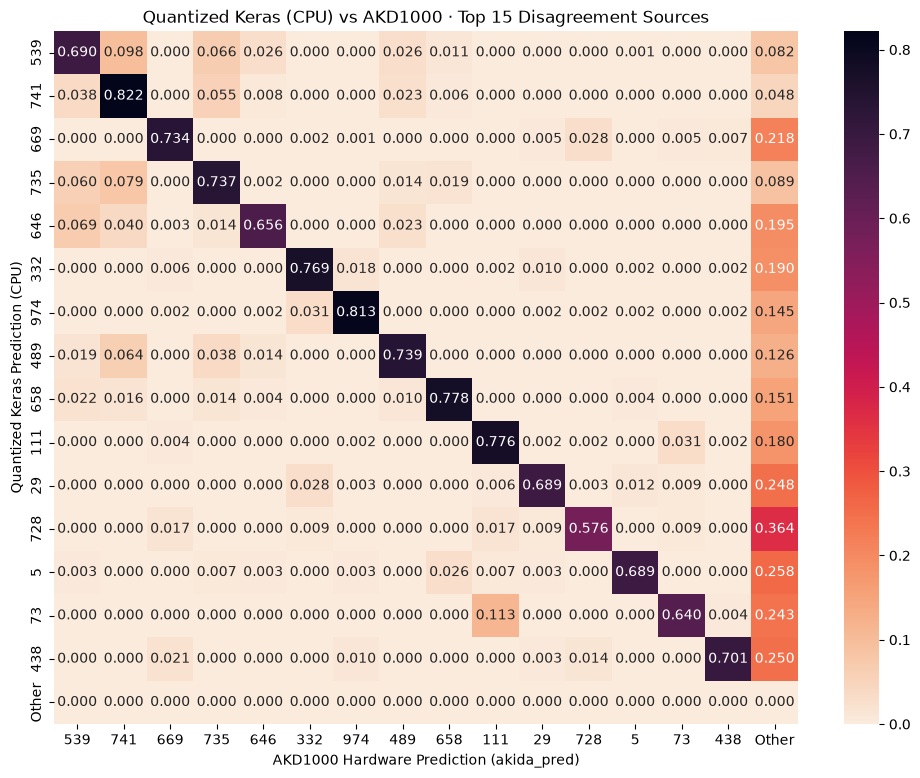

In [4]:
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt=".3f", cmap="rocket_r", 
            xticklabels=tick_labels, yticklabels=tick_labels)
plt.title("Quantized Keras (CPU) vs AKD1000 · Top 15 Disagreement Sources")
plt.xlabel("AKD1000 Hardware Prediction (akida_pred)")
plt.ylabel("Quantized Keras Prediction (CPU)")
plt.savefig("../figures/phase1_human/keras_vs_akida_hardware_shift.png", bbox_inches="tight")
plt.show()

**H4: Low contrast forces a systemic collapse into "textureless" fallback classes (Confusion Matrix View)** <br>
The top classes most degraded by low contrast will systematically shift their predictions into a few specific "fallback" classes that naturally lack fine internal edges or details.

* We reject H4 if: The difference matrix shows the false predictions spreading uniformly across many classes rather than concentrating in 1 or 2 distinct columns.

* To dig deeper: We will identify the specific fallback classes dominating the columns of the difference matrix and inspect the images to understand the shared visual properties (e.g., smooth shapes, gray tones) that cause the model's behavior to default to them.

Max deviation found: 27 images where Keras predicted 73 but Akida hardware predicted 111


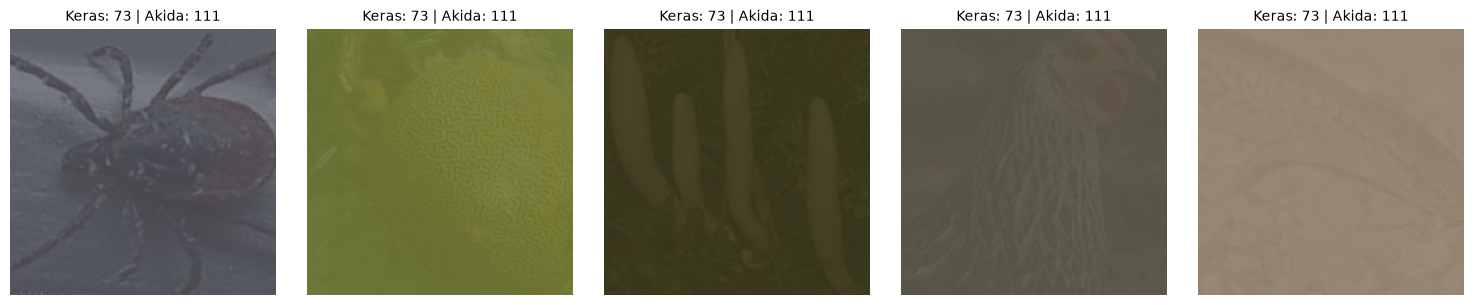

In [ ]:
# find the pair with the biggest error shift
cm_off_diag = cm.copy()
np.fill_diagonal(cm_off_diag, 0)

# remove "9999" (other) column to find only classes that are actually inside our subset
other_idx = cm_labels.index(9999)
cm_off_diag[:, other_idx] = 0

max_idx = np.unravel_index(np.argmax(cm_off_diag, axis=None), cm_off_diag.shape)
KERAS_BASELINE_ID = cm_labels[max_idx[0]]
AKIDA_DEVIATION_ID = cm_labels[max_idx[1]]

drill_down = df_filtered[(df_filtered["keras_pred"] == KERAS_BASELINE_ID) & (df_filtered["akida_pred"] == AKIDA_DEVIATION_ID)]

print(f"Max deviation found: {len(drill_down)} images where Keras predicted {KERAS_BASELINE_ID} but Akida hardware predicted {AKIDA_DEVIATION_ID}")

# plot the first 5 images
fig, axes = plt.subplots(1, min(5, len(drill_down)), figsize=(15, 3))
if len(drill_down) > 0:
    if len(drill_down) == 1: axes = [axes]
        
    for ax, (_, row) in zip(axes, drill_down.head(5).iterrows()):
        img_path = f"../data/imagenet_subset/imagenet-c/{row['corruption']}/{row['severity']}/{row['image_id']}"
        
        try:
            img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
            ax.imshow(img)
        except Exception as e:
            ax.text(0.5, 0.5, 'Image Missing', ha='center', va='center')
            
        ax.axis('off')
        ax.set_title(f"Keras: {row['keras_pred']} | Akida: {row['akida_pred']}", fontsize=10)

plt.tight_layout()
plt.show()

**Conclusion for Hypothesis 4** <br>

Based on the drill-down images showing the maximum deviation between the Keras simulation (Class 73) and the physical Akida hardware (Class 111), we fail to reject Hypothesis 4. The model does indeed systematically collapse into specific fallback classes under low contrast.

**Visual Evidence & Hardware Implications:** <br>
The displayed images share extremely dark, low-contrast conditions where fine, intricate textures (such as insect legs, feathers, and organic ridges) are heavily obscured. Under low contrast, pixel intensity gradients become very weak. 

While the Keras simulator retains enough mathematical precision to classify these features as class 73, the actual Akida hardware relies on 4-bit quantization and event-based spike thresholds. It is highly likely that these weak, low-contrast edges fail to trigger enough spikes on the physical chip (a phenomenon known as "spike death"). Without these crucial high-frequency feature activations, the SNN hardware systematically defaults to the fallback class 111.